# Bayesian Inference with Spectral Constraints: CTCV J2056-3014

This notebook extends the analysis from `07_bayesian_inference.ipynb` by incorporating X-ray spectral constraints ($L_X$ and $kT_{\text{max}}$) directly into the likelihood. This addresses the M–$\dot{M}$ prior correlation from spectral fitting (Salcedo+2024) by replacing informative spectral mass priors with broad population priors, and letting the spectral observables constrain the parameters through the physics.

**Data sources:**
- $\dot{P}_{\rm obs} = 0.0 \pm 1.7 \times 10^{-15}$ s/s (Salcedo+2024, Section 3.3)
- $L_X = 1.8 \times 10^{31}$ erg/s (0.3–12 keV, low state; Salcedo+2024)
- $kT_{\rm max} = 16.3^{+1.9}_{-1.8}$ keV (MKCFLOW; Salcedo+2024, Table 6)

In [17]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.stats import norm
import matplotlib.pyplot as plt
import corner
import dynesty
from dynesty import utils as dyfunc
from dynesty import plotting as dyplot

plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'figure.constrained_layout.use': True,
})

savedir = '../paper_figures' 

## Constants, Data, and WD Mass-Radius-Inertia Relation

In [18]:
# --- Physical constants (CGS) ---
G = 6.674e-8       # cm^3 g^-1 s^-2
Msun = 1.989e33    # g
Rsun = 6.957e10    # cm
m_H = 1.6726e-24   # proton mass [g]
keV_to_erg = 1.602e-9  # keV -> erg

# --- Measured timing data (1-sigma) ---
P = 29.609685843       # spin period [s]
Pdot_obs = 0.0         # observed Pdot [s/s]
sigma_Pdot = 1.7e-15   # 1-sigma uncertainty on Pdot [s/s]

# --- Spectral observables (Salcedo+2024) ---
# X-ray luminosity: F_X(unabs, 0.3-12 keV) = 2.2e-12 erg/s/cm^2, d = 261.6 +/- 7.4 pc
d_pc = 261.6                           # distance [pc]
sigma_d_pc = 7.4                       # 1-sigma distance error [pc]
d_cm = d_pc * 3.086e18                 # distance [cm]
F_X = 2.2e-12                          # unabsorbed flux [erg/s/cm^2]
sigma_FX_frac = 0.05                   # ~5% flux uncertainty (spectral fit)
L_X_obs = 4 * np.pi * d_cm**2 * F_X   # X-ray luminosity [erg/s]
# Propagate distance + flux uncertainties
sigma_LX = L_X_obs * np.sqrt((2 * sigma_d_pc / d_pc)**2 + sigma_FX_frac**2)

# kT_max from MKCFLOW (Salcedo+2024, Table 6)
# 90% CI: 16.3 +1.9/-1.8 keV -> 1-sigma ~ 1.9/1.645 ~ 1.15 keV
kT_obs = 16.3        # keV
sigma_kT = 1.15       # 1-sigma [keV]

# Mean molecular weight for fully ionized solar-composition plasma
mu_mol = 0.617
# Empirical correction factor (Yu+2018, calibrated on 11 nmCVs)
alpha_Yu = 0.646

# --- Load WD mass-radius-inertia table ---
mr_data = np.loadtxt('../wd_mass_radius/mass_radius.txt', delimiter=',', skiprows=1)
M_table = mr_data[:, 0]   # M_sun
R_table = mr_data[:, 1]   # R_sun
I_table = mr_data[:, 2]   # g cm^2

# Interpolators: input in solar masses, output in CGS
get_R = interp1d(M_table, R_table * Rsun, kind='cubic')   # returns cm
get_I = interp1d(M_table, I_table, kind='cubic')           # returns g cm^2

M_min_table = M_table.min()
M_max_table = M_table.max()

xi = 0.5  # magnetospheric radius prefactor (r_m = xi * r_Alfven)

print(f"Table range: {M_min_table:.3f} - {M_max_table:.3f} Msun")
print(f"L_X_obs = {L_X_obs:.2e} erg/s  (sigma = {sigma_LX:.2e})")
print(f"kT_obs  = {kT_obs:.1f} +/- {sigma_kT:.2f} keV (1-sigma)")


Table range: 0.010 - 1.406 Msun
L_X_obs = 1.80e+31 erg/s  (sigma = 1.36e+30)
kT_obs  = 16.3 +/- 1.15 keV (1-sigma)


## Forward Models

**Pdot** models unchanged from `07_bayesian_inference.ipynb` (Bhattacharyya & Chakrabarty 2017).

**New forward models:**

*nmCV:*
- $kT_{\text{pred}} = \frac{3}{16} \alpha \mu_{\text{mol}} m_H \frac{GM}{R}$ (Yu+2018, $\alpha = 0.646$)
- $L_{X,\text{pred}} = \frac{GM\dot{M}}{R}$

*IP:*
- $kT_{\text{pred}} = \frac{3}{8} \mu_{\text{mol}} m_H \cdot 2GM\left(\frac{1}{R} - \frac{1}{r_m}\right)$ (compact shock approximation)
- $L_{X,\text{pred}} = GM\dot{M}\left(\frac{1}{R} - \frac{1}{r_m}\right)$

In [19]:
# =====================================================
# Pdot forward models (same as 07_bayesian_inference)
# =====================================================

def pdot_nmcv(M_wd_solar, log10_Mdot):
    """Predicted Pdot for the nmCV case (disk to surface)."""
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)
    tau = Mdot * np.sqrt(G * M * R)
    return -P**2 * tau / (2 * np.pi * I)


def pdot_ip(M_wd_solar, log10_Mdot, log10_mu):
    """Predicted Pdot for IP case (piecewise disk-magnetosphere torque).

    Accretion phase (r_m <= r_co): Eq 9 of Bhattacharyya & Chakrabarty (2017).
    Propeller phase (r_m > r_co): Eq 10 (eta = 1).
    Returns NaN if r_m <= R_WD (unphysical).
    """
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)

    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)

    if r_m <= R:
        return np.nan

    if r_m <= r_co:
        x = r_m / r_co
        tau_acc = Mdot * np.sqrt(G * M * r_m)
        tau_mag = mu**2 / (9 * r_m**3) * (2 * x**3 - 6 * x**1.5 + 3)
    else:
        tau_acc = -Mdot * np.sqrt(G * M * r_m)
        tau_mag = -mu**2 / (9 * r_m**3) * (3 - 2 * (r_co / r_m)**1.5)

    return -P**2 * (tau_acc + tau_mag) / (2 * np.pi * I)


# =====================================================
# Spectral forward models (new)
# =====================================================

def kT_nmcv(M_wd_solar):
    """Predicted maximum shock temperature for nmCV [keV].

    Uses the Yu+2018 empirical relation for boundary layer CVs:
    kT_max = (3/16) * alpha * mu_mol * m_H * GM/R
    """
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    kT_erg = (3.0 / 16.0) * alpha_Yu * mu_mol * m_H * G * M / R
    return kT_erg / keV_to_erg


def LX_nmcv(M_wd_solar, log10_Mdot):
    """Predicted X-ray luminosity for nmCV [erg/s].

    L_X = G * M * Mdot / R (accretion onto WD surface).
    """
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    return G * M * Mdot / R


def kT_ip(M_wd_solar, log10_Mdot, log10_mu):
    """Predicted shock temperature for IP [keV].

    Compact shock approximation:
    kT = (3/8) * mu_mol * m_H * v_ff^2
    where v_ff^2 = 2GM(1/R - 1/r_m).

    Note: ignores finite shock height h_s. For CJ2056 with h_s/R ~ 20%,
    this overestimates kT by ~10-20%, within the observational uncertainty.
    """
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    if r_m <= R:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT_erg = (3.0 / 8.0) * mu_mol * m_H * vff2
    return kT_erg / keV_to_erg


def LX_ip(M_wd_solar, log10_Mdot, log10_mu):
    """Predicted X-ray luminosity for IP [erg/s].

    L_X = G * M * Mdot * (1/R - 1/r_m), accounting for finite magnetospheric radius.
    """
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    if r_m <= R:
        return np.nan
    return G * M * Mdot * (1.0 / R - 1.0 / r_m)


# --- Sanity checks ---
print("=== Pdot checks ===")
print(f"nmCV(0.935, 15): Pdot = {pdot_nmcv(0.935, 15):.3e}")
print(f"IP(0.815, 15, 30.3): Pdot = {pdot_ip(0.815, 15, 30.3):.3e}")

print("\n=== kT checks ===")
print(f"nmCV kT(0.9): {kT_nmcv(0.9):.1f} keV  (expect ~15-20 keV)")
print(f"IP kT(0.8, 14.5, 30): {kT_ip(0.8, 14.5, 30):.1f} keV  (r_m ~ 1.3R, near observed kT)")
print(f"IP kT(0.8, 14.5, 31): {kT_ip(0.8, 14.5, 31):.1f} keV  (r_m ~ 5R, kT >> observed)")

print("\n=== L_X checks ===")
print(f"nmCV L_X(0.9, 14.5): {LX_nmcv(0.9, 14.5):.2e} erg/s  (expect ~10^31)")
print(f"IP L_X(0.8, 14.5, 31): {LX_ip(0.8, 14.5, 31):.2e} erg/s")


=== Pdot checks ===
nmCV(0.935, 15): Pdot = -2.381e-16
IP(0.815, 15, 30.3): Pdot = -3.262e-16

=== kT checks ===
nmCV kT(0.9): 15.7 keV  (expect ~15-20 keV)
IP kT(0.8, 14.5, 30): 17.9 keV  (r_m ~ 1.3R, near observed kT)
IP kT(0.8, 14.5, 31): 61.2 keV  (r_m ~ 5R, kT >> observed)

=== L_X checks ===
nmCV L_X(0.9, 14.5): 6.35e+31 erg/s  (expect ~10^31)
IP L_X(0.8, 14.5, 31): 4.01e+31 erg/s


## Priors and Likelihood

**Priors**: Broad population-based priors, independent of spectral fits.
- $M_{\rm WD}$: $\mathcal{N}(0.83, 0.20)$ (Pala+2022, volume-limited CV sample), clipped to WD table range
- $\log_{10}\dot{M}$: $\mathcal{U}(13, 17)$ (flat in log-space, covering nmCV through luminous IP range)
- $\log_{10}\mu$ (IP only): $\mathcal{U}(29, 35)$

**Likelihood**: Three observational constraints enter independently:
$$\ln \mathcal{L} = -\frac{1}{2}\left[\left(\frac{\dot{P}_{\rm obs} - \dot{P}_{\rm pred}}{\sigma_{\dot{P}}}\right)^2 + \left(\frac{L_{X,\rm obs} - L_{X,\rm pred}}{\sigma_{L_X}}\right)^2 + \left(\frac{kT_{\rm obs} - kT_{\rm pred}}{\sigma_{kT}}\right)^2\right]$$

In [20]:
# =====================================================
# nmCV model: 2 parameters [M_wd, log10_Mdot]
# =====================================================

# Population mass prior (Pala+2022)
POP_M_MU, POP_M_SIG = 0.83, 0.20

# log10(Mdot) flat prior
LOGMDOT_LO, LOGMDOT_HI = 13.0, 17.0


def prior_transform_nmcv(u):
    """Map unit cube [0,1]^2 -> nmCV parameter space."""
    theta = np.empty(2)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    return theta


def log_likelihood_nmcv(theta):
    """Log-likelihood for nmCV model with Pdot + L_X + kT."""
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    
    Pdot_pred = pdot_nmcv(M_wd, log_Mdot)
    kT_pred = kT_nmcv(M_wd)
    LX_pred = LX_nmcv(M_wd, log_Mdot)
    
    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot)**2
    chi2 += ((kT_obs - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2


# =====================================================
# IP model: 3 parameters [M_wd, log10_Mdot, log10_mu]
# =====================================================

LOGMU_LO, LOGMU_HI = 29.0, 35.0


def prior_transform_ip(u):
    """Map unit cube [0,1]^3 -> IP parameter space."""
    theta = np.empty(3)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    theta[2] = LOGMU_LO + u[2] * (LOGMU_HI - LOGMU_LO)
    return theta


def log_likelihood_ip(theta):
    """Log-likelihood for IP model with Pdot + L_X + kT."""
    M_wd, log_Mdot, log_mu = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    
    Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(Pdot_pred):
        return -1e100
    
    kT_pred = kT_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(kT_pred) or kT_pred <= 0:
        return -1e100
    
    LX_pred = LX_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(LX_pred) or LX_pred <= 0:
        return -1e100
    
    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot)**2
    chi2 += ((kT_obs - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2

## Nested Sampling

In [21]:
print("Running IP nested sampling (3 params, with L_X + kT constraints)...")
sampler_ip = dynesty.DynamicNestedSampler(
    log_likelihood_ip, prior_transform_ip, ndim=3,
    nlive=500, bound='multi', sample='rwalk'
)
sampler_ip.run_nested(print_progress=True)
results_ip = sampler_ip.results
print(f"IP done: logZ = {results_ip['logz'][-1]:.2f} +/- {results_ip['logzerr'][-1]:.2f}")


Running IP nested sampling (3 params, with L_X + kT constraints)...


16018it [00:48, 328.04it/s, batch: 8 | bound: 6 | nc: 1 | ncall: 323838 | eff(%):  4.784 | loglstar: -4.992 < -0.008 < -0.430 | logz: -8.588 +/-  0.070 | stop:  0.890]               

IP done: logZ = -8.57 +/- 0.07


In [22]:
print("Running nmCV nested sampling (2 params, with L_X + kT constraints)...")
sampler_nmcv = dynesty.DynamicNestedSampler(
    log_likelihood_nmcv, prior_transform_nmcv, ndim=2,
    nlive=500, bound='multi', sample='rwalk'
)
sampler_nmcv.run_nested(print_progress=True)
results_nmcv = sampler_nmcv.results
print(f"nmCV done: logZ = {results_nmcv['logz'][-1]:.2f} +/- {results_nmcv['logzerr'][-1]:.2f}")


Running nmCV nested sampling (2 params, with L_X + kT constraints)...


14291it [00:39, 357.50it/s, batch: 8 | bound: 3 | nc: 1 | ncall: 271200 | eff(%):  5.073 | loglstar: -5.147 < -0.000 < -0.535 | logz: -5.902 +/-  0.058 | stop:  0.926]                    


nmCV done: logZ = -5.91 +/- 0.05


## Results

In [23]:
# --- Extract equal-weight posterior samples ---

# IP
weights_ip = np.exp(results_ip['logwt'] - results_ip['logz'][-1])
weights_ip /= weights_ip.sum()
samples_ip_eq = dyfunc.resample_equal(results_ip['samples'], weights_ip)

# Derived: B = mu / R^3
R_samples_ip = np.array([get_R(m) for m in samples_ip_eq[:, 0]])
mu_samples_ip = 10**samples_ip_eq[:, 2]
B_samples_ip = mu_samples_ip / R_samples_ip**3
log10_B_samples_ip = np.log10(B_samples_ip)

# nmCV
weights_nmcv = np.exp(results_nmcv['logwt'] - results_nmcv['logz'][-1])
weights_nmcv /= weights_nmcv.sum()
samples_nmcv_eq = dyfunc.resample_equal(results_nmcv['samples'], weights_nmcv)


# --- Summary statistics ---
def summarize(samples, labels):
    for i, label in enumerate(labels):
        med = np.median(samples[:, i])
        lo, hi = np.percentile(samples[:, i], [16, 84])
        print(f'  {label}: {med:.4f}  (+{hi-med:.4f} / -{med-lo:.4f})')

print('=== IP posteriors ===')
summarize(samples_ip_eq, [r'M_WD [Msun]', r'log10(Mdot) [g/s]', r'log10(mu) [G cm^3]'])
med_B = np.median(log10_B_samples_ip)
lo_B, hi_B = np.percentile(log10_B_samples_ip, [16, 84])
print(f'  log10(B) [G]: {med_B:.2f}  (+{hi_B-med_B:.2f} / -{med_B-lo_B:.2f})')
print(f'  B [MG]: {10**med_B/1e6:.4f}')
print(f'  B [kG]: {10**med_B/1e3:.2f}')

print('\n=== nmCV posteriors ===')
summarize(samples_nmcv_eq, [r'M_WD [Msun]', r'log10(Mdot) [g/s]'])

=== IP posteriors ===
  M_WD [Msun]: 0.6645  (+0.2702 / -0.2560)
  log10(Mdot) [g/s]: 14.7244  (+0.0432 / -0.0430)
  log10(mu) [G cm^3]: 30.2608  (+0.6101 / -0.3193)
  log10(B) [G]: 3.67  (+0.22 / -0.05)
  B [MG]: 0.0046
  B [kG]: 4.65

=== nmCV posteriors ===
  M_WD [Msun]: 0.9123  (+0.0296 / -0.0313)
  log10(Mdot) [g/s]: 13.9395  (+0.0439 / -0.0463)


### Regime-partitioned posterior (IP)

Split the IP posterior into **accretion** ($r_m \le r_{\rm co}$) and **propeller** ($r_m > r_{\rm co}$) branches and report the fraction of posterior mass in each.

*Caveat:* in this (original) notebook the IP likelihood applies the standing-surface-shock $kT$ and $L_X$ models to *all* samples, including those in the propeller branch where that geometry is invalid. The branch partition below is therefore a post-hoc diagnostic of where the posterior lies in $r_m/r_{\rm co}$ space — it does *not* reflect a branch-aware likelihood. See `08_bayesian_spectral_constraints.ipynb` for the corrected likelihood treatment.

Posterior fraction in accretion branch (r_m <= r_co): 0.572
Posterior fraction in propeller branch (r_m >  r_co): 0.428

=== Accretion branch (9157 samples) ===
  M_WD [Msun]            0.819  (+0.196/-0.142)
  log10(Mdot) [g/s]      14.726  (+0.041/-0.045)
  log10(mu) [G cm^3]     30.069  (+0.173/-0.225)
  log10(B) [G]           3.63  (+0.08/-0.03)
  Pdot [s/s]             -2.44e-16  (+2.19e-16/-3.71e-16)

=== Propeller branch (6861 samples) ===
  M_WD [Msun]            0.450  (+0.105/-0.099)
  log10(Mdot) [g/s]      14.722  (+0.046/-0.041)
  log10(mu) [G cm^3]     30.690  (+0.615/-0.256)
  log10(B) [G]           3.77  (+0.47/-0.12)
  Pdot [s/s]             +5.37e-16  (+3.24e-16/-1.79e-16)


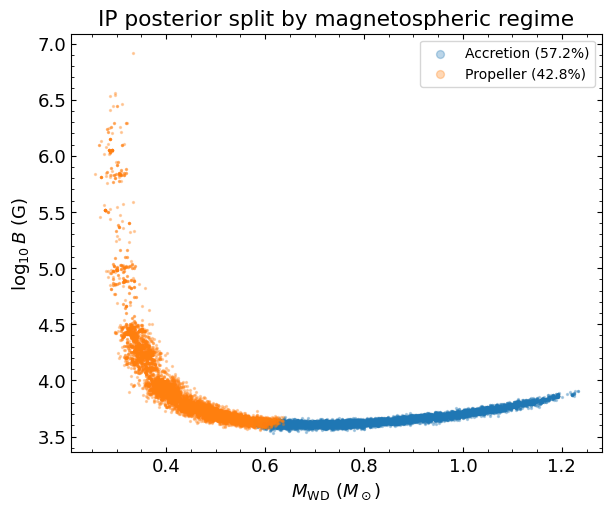

In [24]:
# --- Partition IP posterior into accretion (r_m <= r_co) vs propeller (r_m > r_co) ---
M_post       = samples_ip_eq[:, 0]
logMdot_post = samples_ip_eq[:, 1]
logmu_post   = samples_ip_eq[:, 2]

M_cgs_post = M_post * Msun
Mdot_post  = 10**logMdot_post
mu_post    = 10**logmu_post
r_m_post   = xi * (mu_post**4 / (2 * G * M_cgs_post * Mdot_post**2))**(1.0/7.0)
r_co_post  = (G * M_cgs_post * P**2 / (4 * np.pi**2))**(1.0/3.0)

acc_mask  = r_m_post <= r_co_post
prop_mask = ~acc_mask
f_acc  = acc_mask.mean()
f_prop = prop_mask.mean()

Pdot_ip_samples = np.array([
    pdot_ip(s[0], s[1], s[2]) for s in samples_ip_eq
])

print(f'Posterior fraction in accretion branch (r_m <= r_co): {f_acc:.3f}')
print(f'Posterior fraction in propeller branch (r_m >  r_co): {f_prop:.3f}')


def _branch_stats(mask, name):
    n = int(mask.sum())
    print(f'\n=== {name} branch ({n} samples) ===')
    if n == 0:
        print('  (empty)')
        return
    for i, lbl in enumerate(['M_WD [Msun]', 'log10(Mdot) [g/s]',
                             'log10(mu) [G cm^3]']):
        col = samples_ip_eq[mask, i]
        med = np.median(col); lo, hi = np.percentile(col, [16, 84])
        print(f'  {lbl:<22s} {med:.3f}  (+{hi-med:.3f}/-{med-lo:.3f})')
    col = log10_B_samples_ip[mask]
    med = np.median(col); lo, hi = np.percentile(col, [16, 84])
    print(f'  {"log10(B) [G]":<22s} {med:.2f}  (+{hi-med:.2f}/-{med-lo:.2f})')
    col = Pdot_ip_samples[mask]
    med = np.median(col); lo, hi = np.percentile(col, [16, 84])
    print(f'  {"Pdot [s/s]":<22s} {med:+.2e}  (+{hi-med:.2e}/{lo-med:.2e})')


_branch_stats(acc_mask,  'Accretion')
_branch_stats(prop_mask, 'Propeller')

# Regime-split scatter in (M_WD, log B)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(samples_ip_eq[acc_mask, 0],  log10_B_samples_ip[acc_mask],
           s=2, alpha=0.3, color='C0',
           label=f'Accretion ({f_acc*100:.1f}%)')
ax.scatter(samples_ip_eq[prop_mask, 0], log10_B_samples_ip[prop_mask],
           s=2, alpha=0.3, color='C1',
           label=f'Propeller ({f_prop*100:.1f}%)')
ax.set_xlabel(r'$M_{\rm WD}$ ($M_\odot$)')
ax.set_ylabel(r'$\log_{10} B$ (G)')
ax.set_title('IP posterior split by magnetospheric regime')
ax.legend(markerscale=4, fontsize=10)
fig.savefig(f'{savedir}/bayesian_ip_regime_split_original.pdf', bbox_inches='tight')
plt.show()

### Bayes Factor

In [25]:
logZ_ip = results_ip['logz'][-1]
logZ_ip_err = results_ip['logzerr'][-1]
logZ_nmcv = results_nmcv['logz'][-1]
logZ_nmcv_err = results_nmcv['logzerr'][-1]

print('=== Model Evidence ===')
print(f'  ln(Z_IP)   = {logZ_ip:.2f} +/- {logZ_ip_err:.2f}')
print(f'  ln(Z_nmCV) = {logZ_nmcv:.2f} +/- {logZ_nmcv_err:.2f}')
print()


def jeffreys_scale(abs_lnBF):
    if abs_lnBF < 1:
        return 'Not worth more than a bare mention'
    elif abs_lnBF < 2.5:
        return 'Substantial'
    elif abs_lnBF < 5:
        return 'Strong'
    else:
        return 'Decisive'


lnBF = logZ_ip - logZ_nmcv
lnBF_err = np.sqrt(logZ_ip_err**2 + logZ_nmcv_err**2)
BF = np.exp(lnBF)
strength = jeffreys_scale(abs(lnBF))
favored = 'IP' if lnBF > 0 else 'nmCV'

header = f"{'Comparison':<16} {'ln(BF)':<16} {'BF':<12} Interpretation"
sep = '-' * 65
row = f"{'IP/nmCV':<16} {lnBF:+.2f} +/- {lnBF_err:.2f}  {BF:<12.4f} {strength} ({favored})"
print('=== Bayes Factor ===')
print(header)
print(sep)
print(row)

=== Model Evidence ===
  ln(Z_IP)   = -8.57 +/- 0.07
  ln(Z_nmCV) = -5.91 +/- 0.05

=== Bayes Factor ===
Comparison       ln(BF)           BF           Interpretation
-----------------------------------------------------------------
IP/nmCV          -2.67 +/- 0.09  0.0694       Strong (nmCV)


### Corner Plots

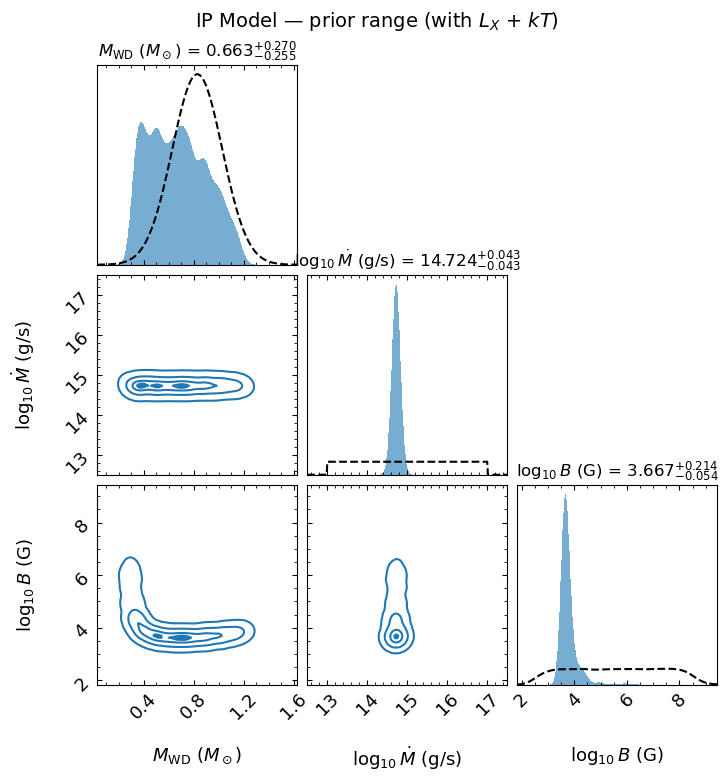

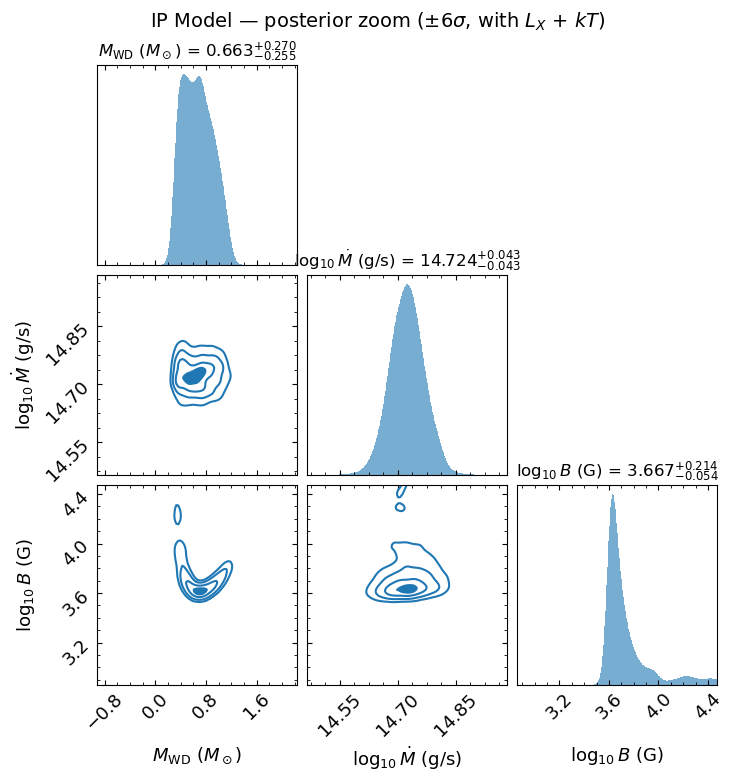

In [26]:
# --- IP corner plot (M_WD, log Mdot, log B) with prior overlays ---
import copy
from scipy.stats import gaussian_kde

results_ip_B = copy.deepcopy(results_ip)
R_arr = np.array([get_R(m) for m in results_ip_B['samples'][:, 0]])
B_arr = 10**results_ip_B['samples'][:, 2] / R_arr**3
results_ip_B['samples'][:, 2] = np.log10(B_arr)

# Compute B prior samples for overlay
np.random.seed(42)
N_prior = 50000
M_prior = np.random.normal(POP_M_MU, POP_M_SIG, N_prior)
M_prior = np.clip(M_prior, M_min_table + 0.001, M_max_table - 0.001)
logmu_prior = np.random.uniform(LOGMU_LO, LOGMU_HI, N_prior)
R_prior = np.array([get_R(m) for m in M_prior])
logB_prior = logmu_prior - 3 * np.log10(R_prior)


def overlay_prior(ax, grid, pdf, **kwargs):
    """Scale prior PDF to match histogram area for correct normalization."""
    hist_area = sum(p.get_width() * p.get_height()
                    for p in ax.patches if p.get_height() > 0)
    if hist_area <= 0:
        return
    prior_area = np.trapezoid(pdf, grid)
    if prior_area <= 0:
        return
    pdf_scaled = pdf * (hist_area / prior_area)
    ax.plot(grid, pdf_scaled, **kwargs)
    ymax = max(ax.get_ylim()[1], pdf_scaled.max() * 1.05)
    ax.set_ylim([0, ymax])


# --- Prior-range view (shows how much priors are updated) ---
span_ip_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
    (np.min(logB_prior), np.max(logB_prior)-3),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B, span=span_ip_wide,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)', r'$\log_{10} B$ (G)'],
    quantiles_2d=[0.1, 0.55, 0.93, 0.999], 
    quantiles = None, show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)

# Overlay priors on diagonals
ax = axes[0, 0]
M_grid = np.linspace(*span_ip_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_ip_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)
ax = axes[2, 2]
kde_B = gaussian_kde(logB_prior)
B_grid = np.linspace(*span_ip_wide[2], 300)
overlay_prior(ax, B_grid, kde_B(B_grid), color='k', ls='--', lw=1.5)

fig.suptitle('IP Model — prior range (with $L_X$ + $kT$)', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

# --- Posterior zoom (shows degeneracy structure) ---
# Adjustable: N sigma around the median to show
N_SIGMA_ZOOM = 6

span_ip_zoom = []
for col in [samples_ip_eq[:, 0], samples_ip_eq[:, 1], log10_B_samples_ip]:
    med = np.median(col)
    sig = (np.percentile(col, 84) - np.percentile(col, 16)) / 2
    span_ip_zoom.append((med - N_SIGMA_ZOOM*sig, med + N_SIGMA_ZOOM*sig))

plt.rcParams['figure.constrained_layout.use'] = False
fig2, axes2 = dyplot.cornerplot(
    results_ip_B, span=span_ip_zoom,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)', r'$\log_{10} B$ (G)'],
    quantiles=None, show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)
fig2.suptitle(r'IP Model — posterior zoom ($\pm$' + f'{N_SIGMA_ZOOM}' + r'$\sigma$, with $L_X$ + $kT$)', fontsize=14, y=1.02)
fig2.savefig(f'{savedir}/bayesian_corner_ip_spectral_zoom.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

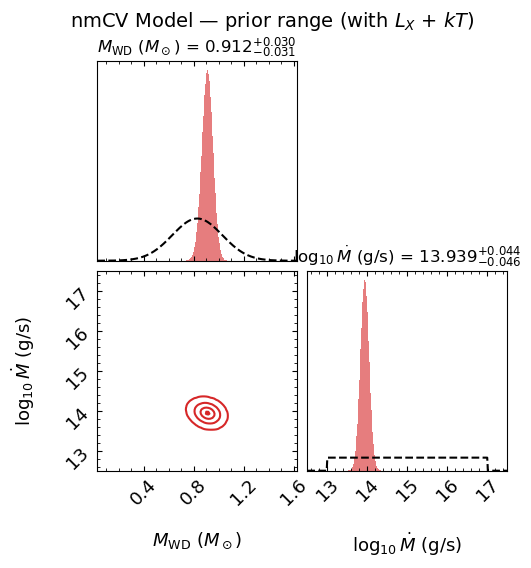

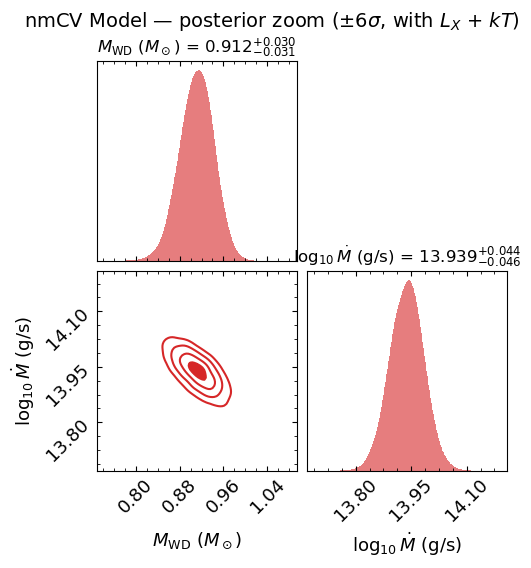

In [27]:
# --- nmCV corner plot (M_WD, log Mdot) with prior overlays ---
span_nmcv_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_nmcv, span=span_nmcv_wide,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=True,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C3',
)

ax = axes[0, 0]
M_grid = np.linspace(*span_nmcv_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_nmcv_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)

fig.suptitle('nmCV Model — prior range (with $L_X$ + $kT$)', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_nmcv_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

# --- Posterior zoom ---
span_nmcv_zoom = []
for col in [samples_nmcv_eq[:, 0], samples_nmcv_eq[:, 1]]:
    med = np.median(col)
    sig = (np.percentile(col, 84) - np.percentile(col, 16)) / 2
    span_nmcv_zoom.append((med - N_SIGMA_ZOOM*sig, med + N_SIGMA_ZOOM*sig))

plt.rcParams['figure.constrained_layout.use'] = False
fig2, axes2 = dyplot.cornerplot(
    results_nmcv, span=span_nmcv_zoom,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C3',
)
fig2.suptitle(r'nmCV Model — posterior zoom ($\pm$' + f'{N_SIGMA_ZOOM}' + r'$\sigma$, with $L_X$ + $kT$)', fontsize=14, y=1.02)
fig2.savefig(f'{savedir}/bayesian_corner_nmcv_spectral_zoom.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

### Predicted $\dot{P}$ Distribution

nmCV:  Pdot = -1.99e-17  (+1.54e-18 / -1.60e-18)
       range = [-2.65e-17, -1.36e-17]
       100.0% within 1-sigma of Pdot=0;  100.0% within 2-sigma

IP:  Pdot = -2.71e-18  (+6.34e-16 / -4.39e-16)
       range = [-1.52e-15, 4.65e-15]
       99.0% within 1-sigma of Pdot=0;  99.9% within 2-sigma



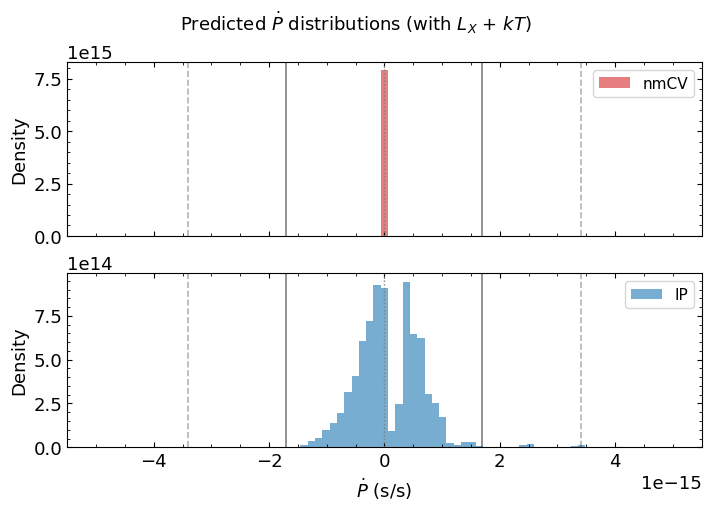

In [28]:
# Compute Pdot from posterior samples
Pdot_nmcv_samples = np.array([
    pdot_nmcv(s[0], s[1]) for s in samples_nmcv_eq
])
Pdot_ip_samples = np.array([
    pdot_ip(s[0], s[1], s[2]) for s in samples_ip_eq
])

# --- Print summary statistics ---
for name, samp in [('nmCV', Pdot_nmcv_samples), ('IP', Pdot_ip_samples)]:
    med = np.median(samp)
    lo, hi = np.percentile(samp, [16, 84])
    mn, mx = samp.min(), samp.max()
    print(f"{name}:  Pdot = {med:.2e}  (+{hi-med:.2e} / {lo-med:.2e})")
    print(f"       range = [{mn:.2e}, {mx:.2e}]")
    frac_consistent = np.mean(np.abs(samp) < sigma_Pdot) * 100
    frac_2sig = np.mean(np.abs(samp) < 2*sigma_Pdot) * 100
    print(f"       {frac_consistent:.1f}% within 1-sigma of Pdot=0;  {frac_2sig:.1f}% within 2-sigma")
    print()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(7, 5), sharex=True,
                                      gridspec_kw={'height_ratios': [1, 1]})

bins = np.linspace(-5e-15, 5e-15, 80)
ax_top.hist(Pdot_nmcv_samples, bins=bins, density=True, alpha=0.6, color='C3', label='nmCV')
ax_bot.hist(Pdot_ip_samples, bins=bins, density=True, alpha=0.6, color='C0', label='IP')

for ax in [ax_top, ax_bot]:
    ax.axvline(0, color='gray', ls=':', lw=1)
    for nsig, ls, alph in [(1, '-', 0.5), (2, '--', 0.3)]:
        ax.axvline(nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
        ax.axvline(-nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
    ax.legend(fontsize=11)
    ax.set_ylabel('Density')

ax_bot.set_xlabel(r'$\dot{P}$ (s/s)')
fig.suptitle(r'Predicted $\dot{P}$ distributions (with $L_X$ + $kT$)', fontsize=13)
fig.savefig(f'{savedir}/bayesian_pdot_posterior_spectral.pdf', bbox_inches='tight')
plt.show()

### Posterior Predictive Check

Compare the predicted observables ($kT$, $L_X$) from the posterior to the observed values.
This verifies the models actually reproduce the spectral data, and shows the per-observable
$\chi^2$ contribution.

=== Per-observable chi^2 (median of posterior) ===

nmCV:
  chi2(Pdot) = 0.00
  chi2(kT)   = 0.46
  chi2(L_X)  = 0.46
  total      = 0.93

IP:
  chi2(Pdot) = 0.06
  chi2(kT)   = 0.42
  chi2(L_X)  = 0.42
  total      = 0.90



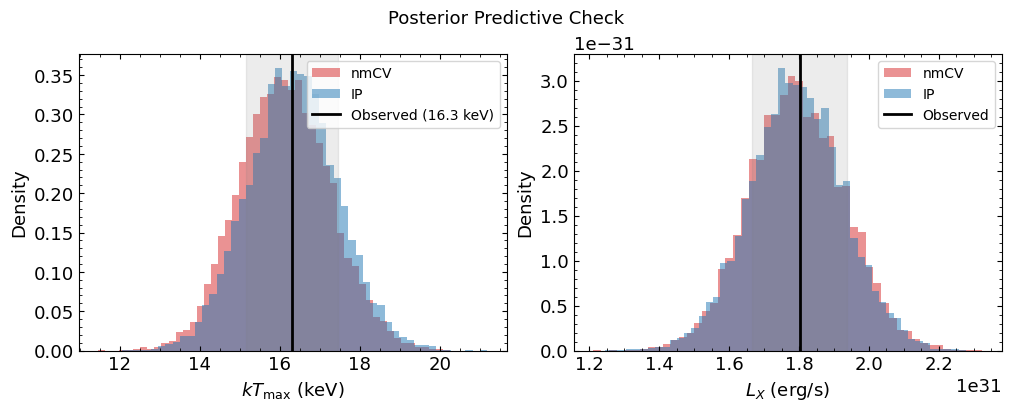

In [29]:
# --- Predicted kT and L_X from posterior ---
kT_nmcv_pred = np.array([kT_nmcv(s[0]) for s in samples_nmcv_eq])
LX_nmcv_pred = np.array([LX_nmcv(s[0], s[1]) for s in samples_nmcv_eq])

kT_ip_pred = np.array([kT_ip(s[0], s[1], s[2]) for s in samples_ip_eq])
LX_ip_pred = np.array([LX_ip(s[0], s[1], s[2]) for s in samples_ip_eq])
# filter NaN from IP
valid_ip = np.isfinite(kT_ip_pred) & np.isfinite(LX_ip_pred)

# --- Chi-squared breakdown ---
print("=== Per-observable chi^2 (median of posterior) ===\n")
for name, Pdot_s, kT_s, LX_s in [
    ('nmCV', Pdot_nmcv_samples, kT_nmcv_pred, LX_nmcv_pred),
    ('IP', Pdot_ip_samples, kT_ip_pred[valid_ip], LX_ip_pred[valid_ip]),
]:
    chi2_Pdot = np.median(((Pdot_obs - Pdot_s) / sigma_Pdot)**2)
    chi2_kT = np.median(((kT_obs - kT_s) / sigma_kT)**2)
    chi2_LX = np.median(((L_X_obs - LX_s) / sigma_LX)**2)
    print(f"{name}:")
    print(f"  chi2(Pdot) = {chi2_Pdot:.2f}")
    print(f"  chi2(kT)   = {chi2_kT:.2f}")
    print(f"  chi2(L_X)  = {chi2_LX:.2f}")
    print(f"  total      = {chi2_Pdot + chi2_kT + chi2_LX:.2f}")
    print()

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# kT panel
ax = axes[0]
ax.hist(kT_nmcv_pred, bins=50, density=True, alpha=0.5, color='C3', label='nmCV')
ax.hist(kT_ip_pred[valid_ip], bins=50, density=True, alpha=0.5, color='C0', label='IP')
ax.axvline(kT_obs, color='k', lw=2, label=f'Observed ({kT_obs} keV)')
ax.axvspan(kT_obs - sigma_kT, kT_obs + sigma_kT, alpha=0.15, color='gray')
ax.set_xlabel(r'$kT_{\rm max}$ (keV)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

# L_X panel
ax = axes[1]
ax.hist(LX_nmcv_pred, bins=50, density=True, alpha=0.5, color='C3', label='nmCV')
ax.hist(LX_ip_pred[valid_ip], bins=50, density=True, alpha=0.5, color='C0', label='IP')
ax.axvline(L_X_obs, color='k', lw=2, label=f'Observed')
ax.axvspan(L_X_obs - sigma_LX, L_X_obs + sigma_LX, alpha=0.15, color='gray')
ax.set_xlabel(r'$L_X$ (erg/s)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

fig.suptitle('Posterior Predictive Check', fontsize=13)
fig.savefig(f'{savedir}/bayesian_predictive_check_spectral.pdf', bbox_inches='tight')
plt.show()

## Impact of $\dot{P}$ Measurement

Compare results with the **new** timing constraint ($\sigma_{\dot{P}} = 1.7 \times 10^{-15}$ s/s)
versus the **old** constraint ($\sigma_{\dot{P}} = 1.8 \times 10^{-12}$ s/s, essentially no Pdot information).
This isolates how much the improved timing measurement adds beyond the spectral constraints alone.

In [30]:
# --- Re-run with old (weak) Pdot constraint ---
sigma_Pdot_old = 1.8e-12  # old 1-sigma: essentially no constraint

def log_likelihood_nmcv_old(theta):
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    Pdot_pred = pdot_nmcv(M_wd, log_Mdot)
    kT_pred = kT_nmcv(M_wd)
    LX_pred = LX_nmcv(M_wd, log_Mdot)
    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot_old)**2
    chi2 += ((kT_obs - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2

def log_likelihood_ip_old(theta):
    M_wd, log_Mdot, log_mu = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(Pdot_pred):
        return -1e100
    kT_pred = kT_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(kT_pred) or kT_pred <= 0:
        return -1e100
    LX_pred = LX_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(LX_pred) or LX_pred <= 0:
        return -1e100
    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot_old)**2
    chi2 += ((kT_obs - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2

# Use static NestedSampler (faster convergence for comparison runs)
print("Running IP sampling with OLD Pdot constraint...")
sampler_ip_old = dynesty.NestedSampler(
    log_likelihood_ip_old, prior_transform_ip, ndim=3,
    nlive=1000, bound='multi', sample='rwalk'
)
sampler_ip_old.run_nested(print_progress=True, dlogz=0.1)
results_ip_old = sampler_ip_old.results
print(f"IP (old): logZ = {results_ip_old['logz'][-1]:.2f} +/- {results_ip_old['logzerr'][-1]:.2f}")

print("\nRunning nmCV sampling with OLD Pdot constraint...")
sampler_nmcv_old = dynesty.NestedSampler(
    log_likelihood_nmcv_old, prior_transform_nmcv, ndim=2,
    nlive=1000, bound='multi', sample='rwalk'
)
sampler_nmcv_old.run_nested(print_progress=True, dlogz=0.1)
results_nmcv_old = sampler_nmcv_old.results
print(f"nmCV (old): logZ = {results_nmcv_old['logz'][-1]:.2f} +/- {results_nmcv_old['logzerr'][-1]:.2f}")


Running IP sampling with OLD Pdot constraint...


10964it [00:28, 384.82it/s, +1000 | bound: 16 | nc: 1 | ncall: 207858 | eff(%):  5.784 | loglstar:   -inf < -0.000 <    inf | logz: -8.624 +/-    nan | dlogz:  0.000 >  0.100]  


IP (old): logZ = -8.62 +/- 0.11

Running nmCV sampling with OLD Pdot constraint...


8177it [00:18, 453.99it/s, +1000 | bound: 5 | nc: 1 | ncall: 137103 | eff(%):  6.743 | loglstar:   -inf < -0.000 <    inf | logz: -5.825 +/-  0.070 | dlogz:  0.000 >  0.100]    

nmCV (old): logZ = -5.82 +/- 0.09


In [31]:
# --- Extract old-constraint posteriors ---
w_ip_old = np.exp(results_ip_old['logwt'] - results_ip_old['logz'][-1])
w_ip_old /= w_ip_old.sum()
samples_ip_old_eq = dyfunc.resample_equal(results_ip_old['samples'], w_ip_old)

w_nmcv_old = np.exp(results_nmcv_old['logwt'] - results_nmcv_old['logz'][-1])
w_nmcv_old /= w_nmcv_old.sum()
samples_nmcv_old_eq = dyfunc.resample_equal(results_nmcv_old['samples'], w_nmcv_old)

# Derived B for IP old
R_old = np.array([get_R(m) for m in samples_ip_old_eq[:, 0]])
log10_B_old = samples_ip_old_eq[:, 2] - 3 * np.log10(R_old)

# --- Comparison table ---
def fmt(samples, idx):
    med = np.median(samples[:, idx])
    lo, hi = np.percentile(samples[:, idx], [16, 84])
    return f"{med:.3f} (+{hi-med:.3f}/-{med-lo:.3f})"

print("=== Posterior comparison: new vs old Pdot constraint ===\n")
header = f"{'Parameter':<22s} {'nmCV (new)':<28s} {'nmCV (old)':<28s}"
print(header)
print("-" * len(header))
print(f"{'M_WD [Msun]':<22s} {fmt(samples_nmcv_eq, 0):<28s} {fmt(samples_nmcv_old_eq, 0):<28s}")
print(f"{'log10(Mdot) [g/s]':<22s} {fmt(samples_nmcv_eq, 1):<28s} {fmt(samples_nmcv_old_eq, 1):<28s}")
print()

header = f"{'Parameter':<22s} {'IP (new)':<28s} {'IP (old)':<28s}"
print(header)
print("-" * len(header))
print(f"{'M_WD [Msun]':<22s} {fmt(samples_ip_eq, 0):<28s} {fmt(samples_ip_old_eq, 0):<28s}")
print(f"{'log10(Mdot) [g/s]':<22s} {fmt(samples_ip_eq, 1):<28s} {fmt(samples_ip_old_eq, 1):<28s}")
print(f"{'log10(mu) [G cm^3]':<22s} {fmt(samples_ip_eq, 2):<28s} {fmt(samples_ip_old_eq, 2):<28s}")

med_B_new = np.median(log10_B_samples_ip)
med_B_old = np.median(log10_B_old)
lo_B_new, hi_B_new = np.percentile(log10_B_samples_ip, [16, 84])
lo_B_old, hi_B_old = np.percentile(log10_B_old, [16, 84])
new_B = f"{med_B_new:.2f} (+{hi_B_new-med_B_new:.2f}/-{med_B_new-lo_B_new:.2f})"
old_B = f"{med_B_old:.2f} (+{hi_B_old-med_B_old:.2f}/-{med_B_old-lo_B_old:.2f})"
print(f"{'log10(B) [G]':<22s} {new_B:<28s} {old_B:<28s}")

print("\n=== Bayes factor comparison ===")
logZ_ip_new = results_ip['logz'][-1]
logZ_nmcv_new = results_nmcv['logz'][-1]
logZ_ip_o = results_ip_old['logz'][-1]
logZ_nmcv_o = results_nmcv_old['logz'][-1]
lnBF_new = logZ_ip_new - logZ_nmcv_new
lnBF_old = logZ_ip_o - logZ_nmcv_o
print(f"  ln(BF_IP/nmCV) new Pdot: {lnBF_new:+.2f}  (BF = {np.exp(lnBF_new):.4f})")
print(f"  ln(BF_IP/nmCV) old Pdot: {lnBF_old:+.2f}  (BF = {np.exp(lnBF_old):.4f})")

=== Posterior comparison: new vs old Pdot constraint ===

Parameter              nmCV (new)                   nmCV (old)                  
--------------------------------------------------------------------------------
M_WD [Msun]            0.912 (+0.030/-0.031)        0.914 (+0.029/-0.031)       
log10(Mdot) [g/s]      13.940 (+0.044/-0.046)       13.938 (+0.042/-0.045)      

Parameter              IP (new)                     IP (old)                    
--------------------------------------------------------------------------------
M_WD [Msun]            0.665 (+0.270/-0.256)        0.590 (+0.198/-0.279)       
log10(Mdot) [g/s]      14.724 (+0.043/-0.043)       14.721 (+0.048/-0.040)      
log10(mu) [G cm^3]     30.261 (+0.610/-0.319)       30.374 (+1.977/-0.275)      
log10(B) [G]           3.67 (+0.22/-0.05)           3.67 (+1.54/-0.06)          

=== Bayes factor comparison ===
  ln(BF_IP/nmCV) new Pdot: -2.67  (BF = 0.0694)
  ln(BF_IP/nmCV) old Pdot: -2.80  (BF = 0.0608)


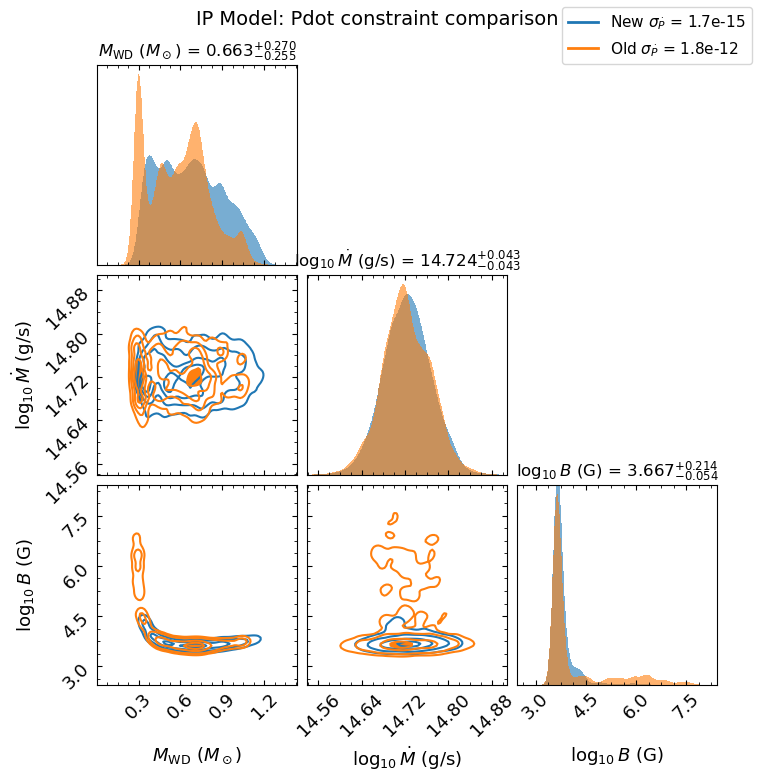

In [32]:
# --- Overlay IP corner plots: new (blue) vs old (orange) Pdot constraint ---
results_ip_B_new = copy.deepcopy(results_ip)
R_tmp = np.array([get_R(m) for m in results_ip_B_new['samples'][:, 0]])
results_ip_B_new['samples'][:, 2] = np.log10(10**results_ip_B_new['samples'][:, 2] / R_tmp**3)

results_ip_B_old = copy.deepcopy(results_ip_old)
R_tmp = np.array([get_R(m) for m in results_ip_B_old['samples'][:, 0]])
results_ip_B_old['samples'][:, 2] = np.log10(10**results_ip_B_old['samples'][:, 2] / R_tmp**3)

# Span encompassing both posteriors
all_ip = np.vstack([samples_ip_eq, samples_ip_old_eq])
all_B = np.concatenate([log10_B_samples_ip, log10_B_old])
span_ip_cmp = []
for col in [all_ip[:, 0], all_ip[:, 1], all_B]:
    lo, hi = np.percentile(col, [0.5, 99.5])
    w = hi - lo
    span_ip_cmp.append((lo - 0.3*w, hi + 0.3*w))

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B_new, span=span_ip_cmp,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)', r'$\log_{10} B$ (G)'],
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    #quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    color='C0',
)
dyplot.cornerplot(
    results_ip_B_old, span=span_ip_cmp,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)', r'$\log_{10} B$ (G)'],
    quantiles=None, show_titles=False,
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    #quantiles_2d=[0.1, 0.4, 0.65, 0.85],
    #quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    color='C1', fig=(fig, axes),
)
from matplotlib.lines import Line2D
fig.legend(handles=[
    Line2D([0], [0], color='C0', lw=2, label=r'New $\sigma_{\dot{P}}$ = 1.7e-15'),
    Line2D([0], [0], color='C1', lw=2, label=r'Old $\sigma_{\dot{P}}$ = 1.8e-12'),
], loc='upper right', fontsize=11, frameon=True)
fig.suptitle('IP Model: Pdot constraint comparison', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_pdot_comparison.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

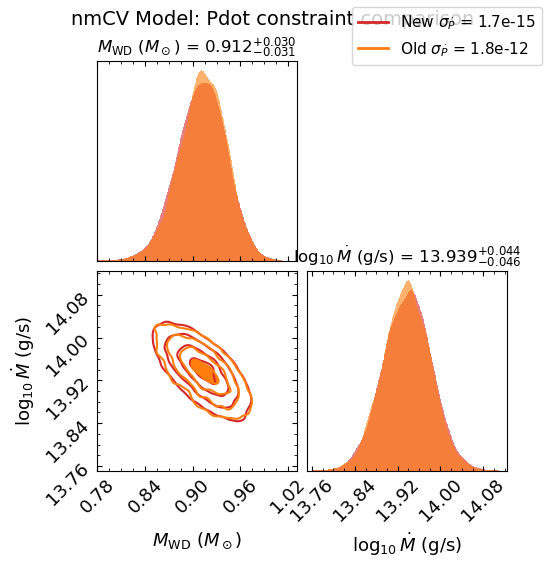

In [33]:
# --- Overlay nmCV corner plots: new (red) vs old (orange) Pdot constraint ---
all_nmcv = np.vstack([samples_nmcv_eq, samples_nmcv_old_eq])
span_nmcv_cmp = []
for col in [all_nmcv[:, 0], all_nmcv[:, 1]]:
    lo, hi = np.percentile(col, [0.5, 99.5])
    w = hi - lo
    span_nmcv_cmp.append((lo - 0.3*w, hi + 0.3*w))

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_nmcv, span=span_nmcv_cmp,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C3',
)
dyplot.cornerplot(
    results_nmcv_old, span=span_nmcv_cmp,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=False,
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C1', fig=(fig, axes),
)
fig.legend(handles=[
    Line2D([0], [0], color='C3', lw=2, label=r'New $\sigma_{\dot{P}}$ = 1.7e-15'),
    Line2D([0], [0], color='C1', lw=2, label=r'Old $\sigma_{\dot{P}}$ = 1.8e-12'),
], loc='upper right', fontsize=11, frameon=True)
fig.suptitle('nmCV Model: Pdot constraint comparison', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_nmcv_pdot_comparison.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

## Summary

This analysis addresses the M–$\dot{M}$ prior correlation from spectral fitting by:
1. Replacing informative spectral mass priors with broad population priors
2. Including $L_X$ and $kT_{\text{max}}$ as observational constraints in the likelihood
3. The physical equations $L_X = GM\dot{M}/R$ and $kT \propto GM/R$ naturally encode the M–$\dot{M}$ anticorrelation

The $L_X$ constraint pins $\dot{M}$ to $\sim 10^{14}$ g/s (consistent with CJ2056 being a low-luminosity IP), which propagates through $r_m \propto (\mu^4/\dot{M}^2)^{1/7}$ to tighten the $\mu$ (and thus $B$) posterior.